<a href="https://colab.research.google.com/github/pual113-png/TEST1/blob/main/SK_Energy_RT_YOLO26x%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

dataset = "/content/drive/MyDrive/RT_weld_project/weld_yolo"

print("데이터셋 존재:", os.path.exists(dataset))
print("data.yaml 존재:", os.path.exists(dataset + "/data.yaml"))
print("train images 존재:", os.path.exists(dataset + "/images/train"))
print("val images 존재:", os.path.exists(dataset + "/images/val"))

Mounted at /content/drive
데이터셋 존재: True
data.yaml 존재: True
train images 존재: True
val images 존재: True


In [ ]:
!rm -rf /content/weld_yolo

!rsync -a --info=progress2 \
  /content/drive/MyDrive/RT_weld_project/weld_yolo/ \
  /content/weld_yolo/

import os

print("\n=== 복사 확인 ===")
print("data.yaml:", os.path.exists("/content/weld_yolo/data.yaml"))
print("train images:", len(os.listdir("/content/weld_yolo/images/train")))
print("val images:", len(os.listdir("/content/weld_yolo/images/val")))
print("train labels:", len(os.listdir("/content/weld_yolo/labels/train")))
print("val labels:", len(os.listdir("/content/weld_yolo/labels/val")))

    411,225,908 100%  159.81kB/s    0:41:52 (xfr#6817, to-chk=0/6824)

=== 복사 확인 ===
data.yaml: True
train images: 2726
val images: 682
train labels: 2726
val labels: 682


In [ ]:
!pip install -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 6.9 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26x.pt")

print("YOLO26x 로드 완료")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO26x 로드 완료


In [ ]:
results = model.train(
    data="/content/weld_yolo/data.yaml",
    epochs=300,
    imgsz=640,
    batch=-1,
    device=0,
    project="/content/drive/MyDrive/RT_weld_project/runs_yolo26",
    name="yolo26x_300",
    save=True,
    save_period=10,
    patience=0,
    plots=True
)

Ultralytics 8.4.172 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/weld_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26x.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26x_300, nbs=64, nms=None, opset=None, optimize=False,

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

path = "/content/drive/MyDrive/RT_weld_project/runs_yolo26/yolo26x_300/weights"

print("weights 폴더 존재:", os.path.exists(path))

if os.path.exists(path):
    print(os.listdir(path))

weights 폴더 존재: True
['epoch0.pt', 'epoch10.pt', 'epoch20.pt', 'epoch30.pt', 'epoch40.pt', 'epoch50.pt', 'epoch60.pt', 'epoch70.pt', 'epoch80.pt', 'epoch90.pt', 'epoch100.pt', 'epoch110.pt', 'epoch120.pt', 'epoch130.pt', 'best.pt', 'epoch140.pt', 'epoch150.pt', 'epoch160.pt', 'epoch170.pt', 'epoch180.pt', 'epoch190.pt', 'last.pt']


In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/RT_weld_project/runs_yolo26/yolo26x_300/weights/last.pt"
)

model.train(resume=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/weld_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bee75550210>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

In [ ]:
from ultralytics import YOLO
import os

best_path = "/content/drive/MyDrive/RT_weld_project/runs_yolo26/yolo26x_300/weights/best.pt"

print("best.pt 존재:", os.path.exists(best_path))

model_best = YOLO(best_path)

metrics = model_best.val(
    data="/content/weld_yolo/data.yaml",
    imgsz=640,
    split="val"
)

print("\n=== YOLO26x 최종 성능 ===")
print(f"Precision      : {metrics.box.mp:.5f}")
print(f"Recall         : {metrics.box.mr:.5f}")
print(f"mAP@0.5        : {metrics.box.map50:.5f}")
print(f"mAP@0.5:0.95   : {metrics.box.map:.5f}")

best.pt 존재: True
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26x summary (fused): 188 layers, 55,642,788 parameters, 0 gradients, 194.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2145.4±687.0 MB/s, size: 115.3 KB)
val: Scanning /content/weld_yolo/labels/val.cache... 682 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 682/682 204.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 2.9it/s 15.0s
                   all        682       1338      0.976      0.989      0.989      0.731
              air-hole        423       1035      0.949      0.948      0.966      0.501
             bite-edge          8          8          1          1      0.995      0.666
            broken-arc         88         88      0.971          1      0.995      0.928
                 crack         22         22          1       0.98      0.995      0.688
           hollow-bea

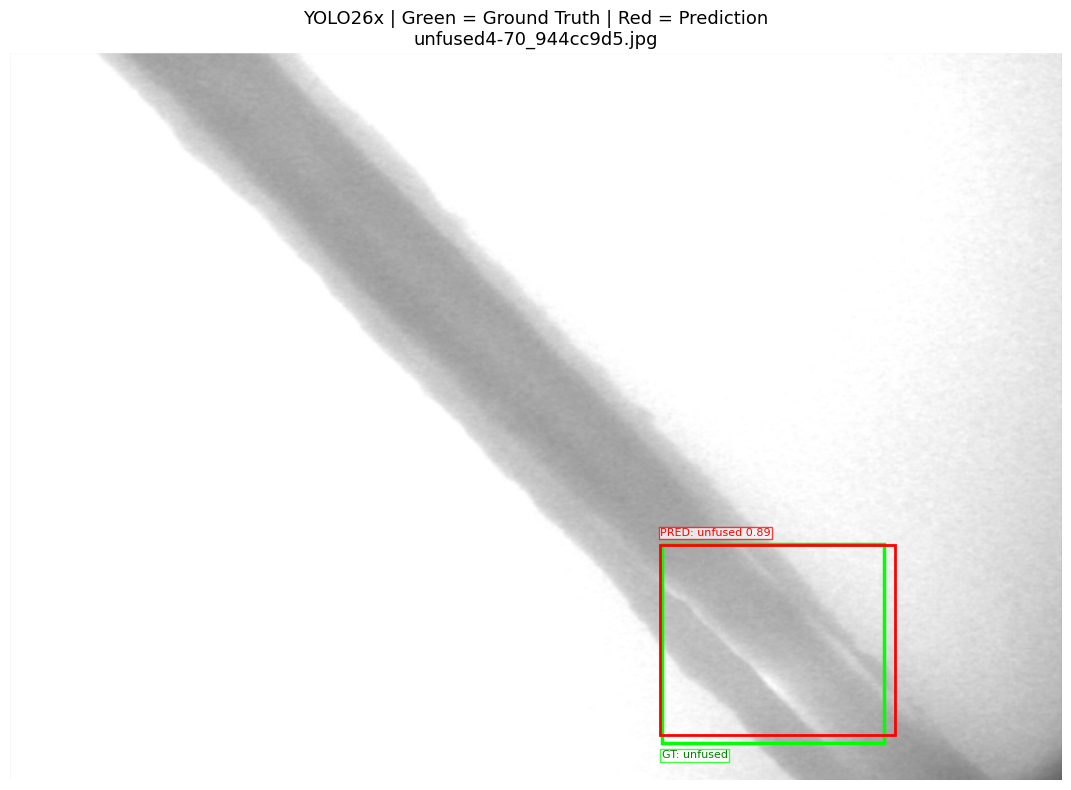

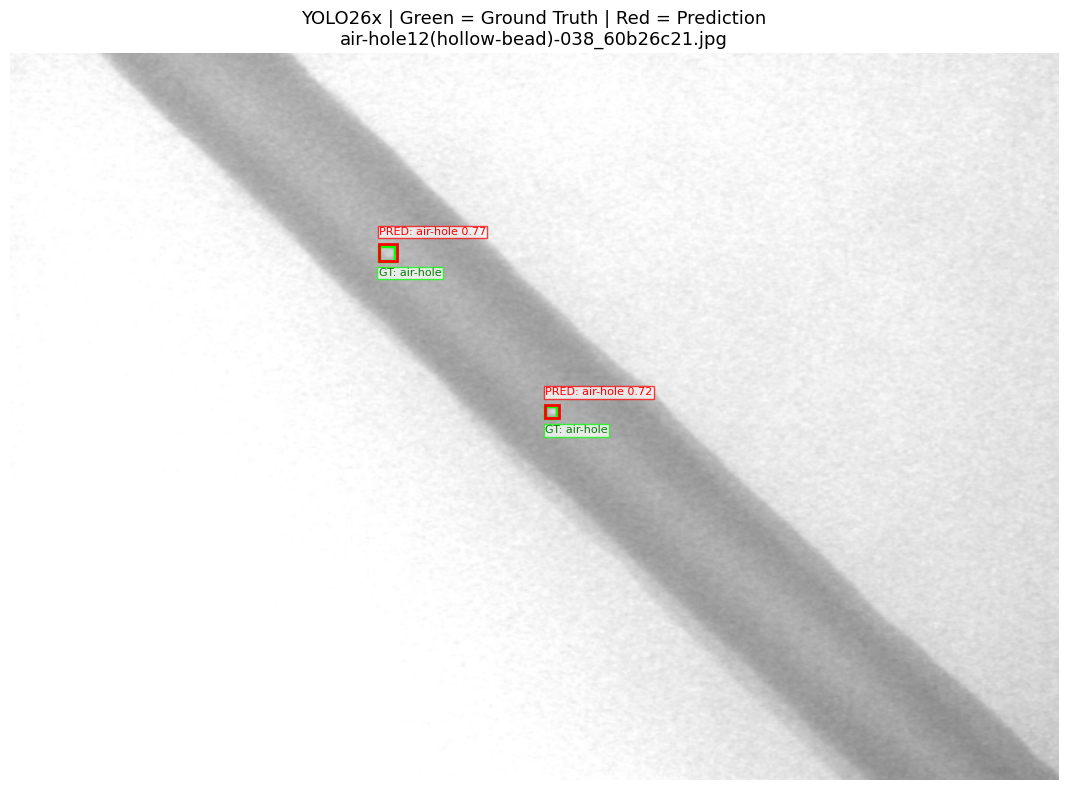

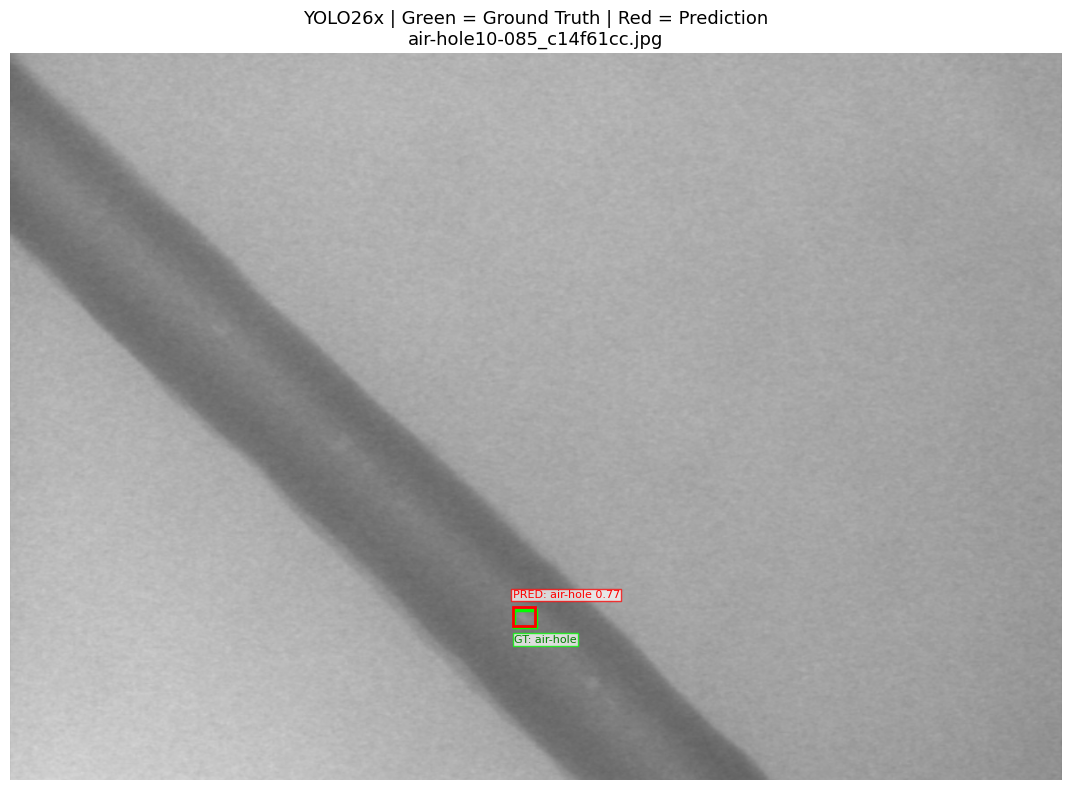

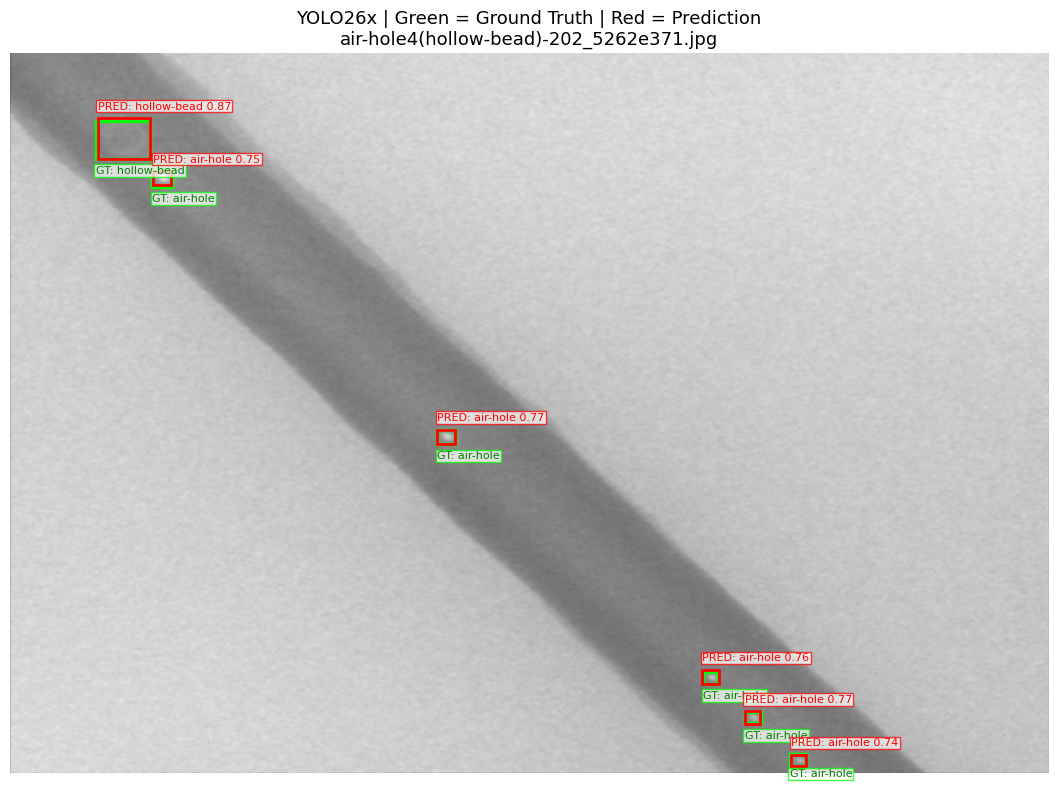

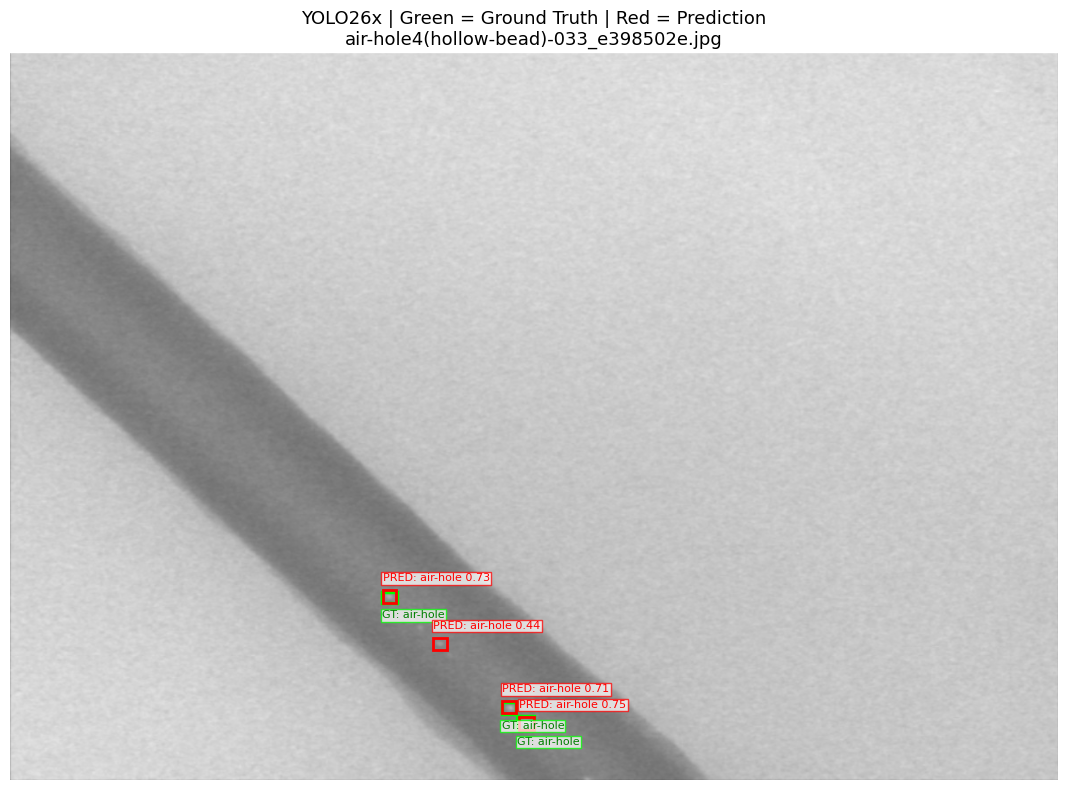

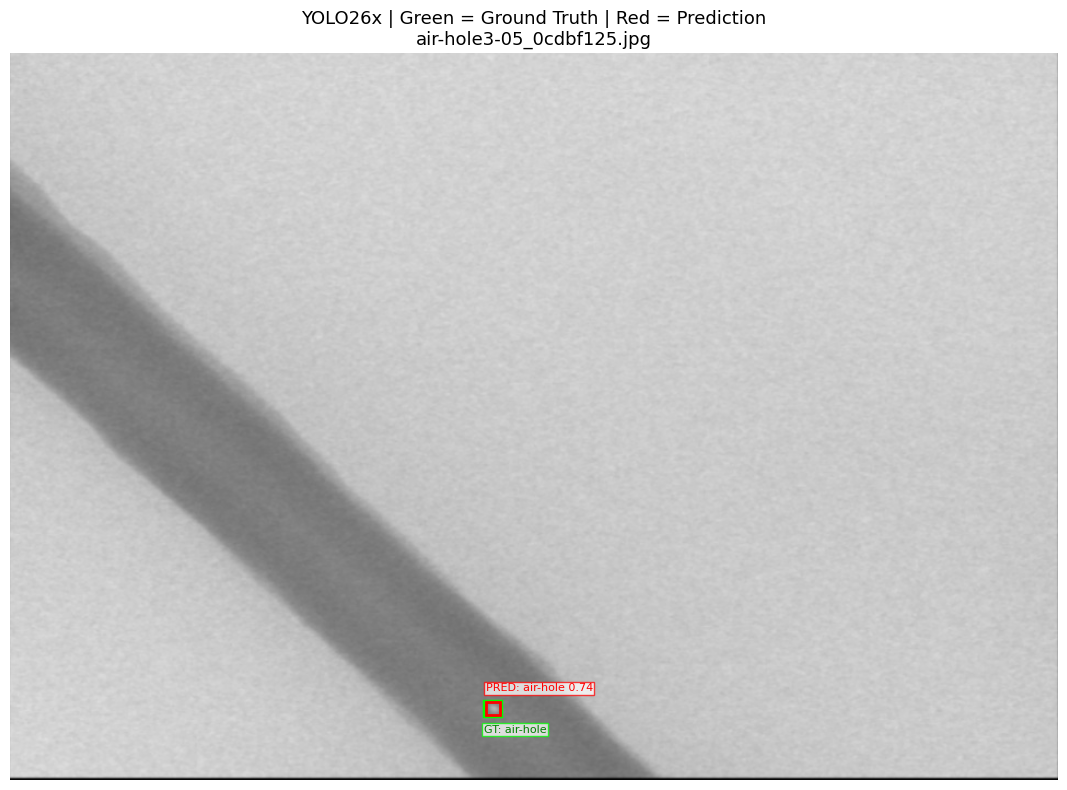

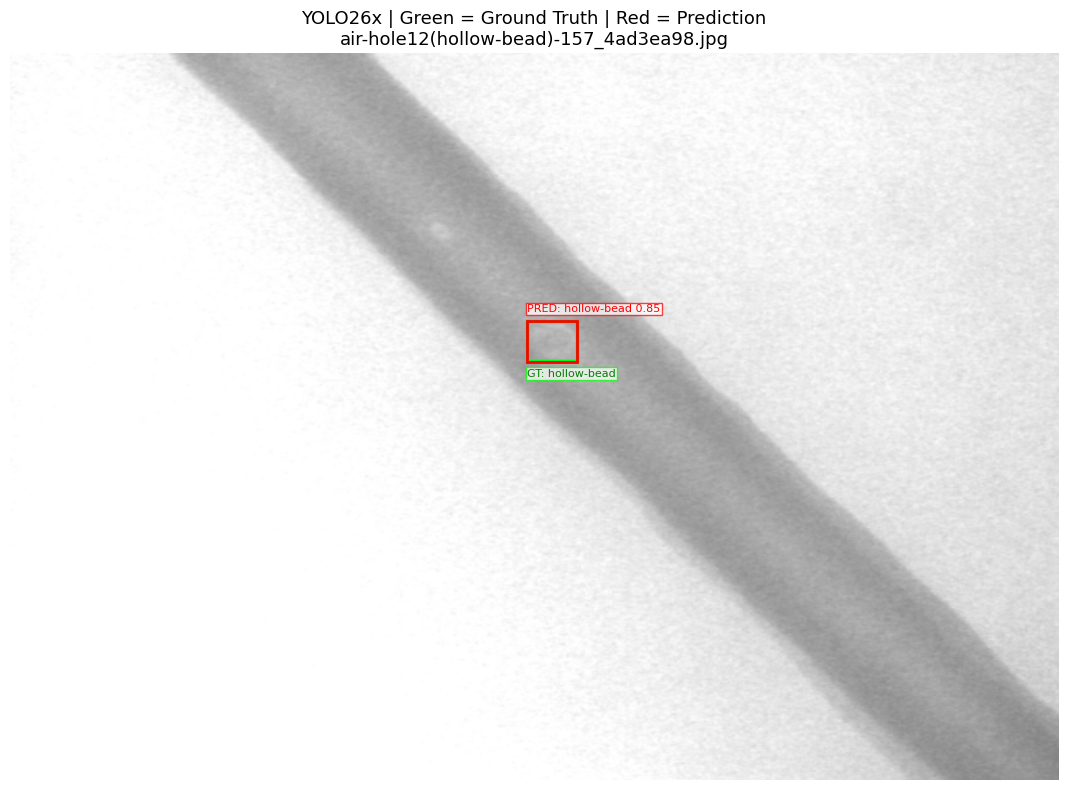

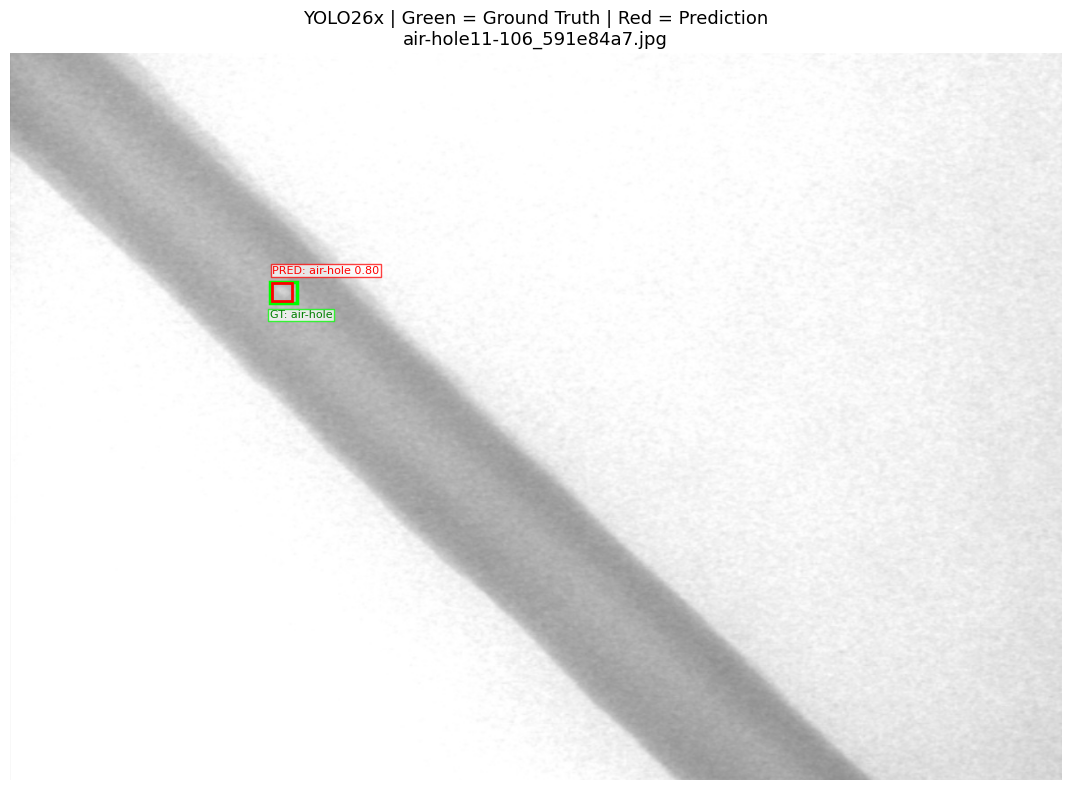

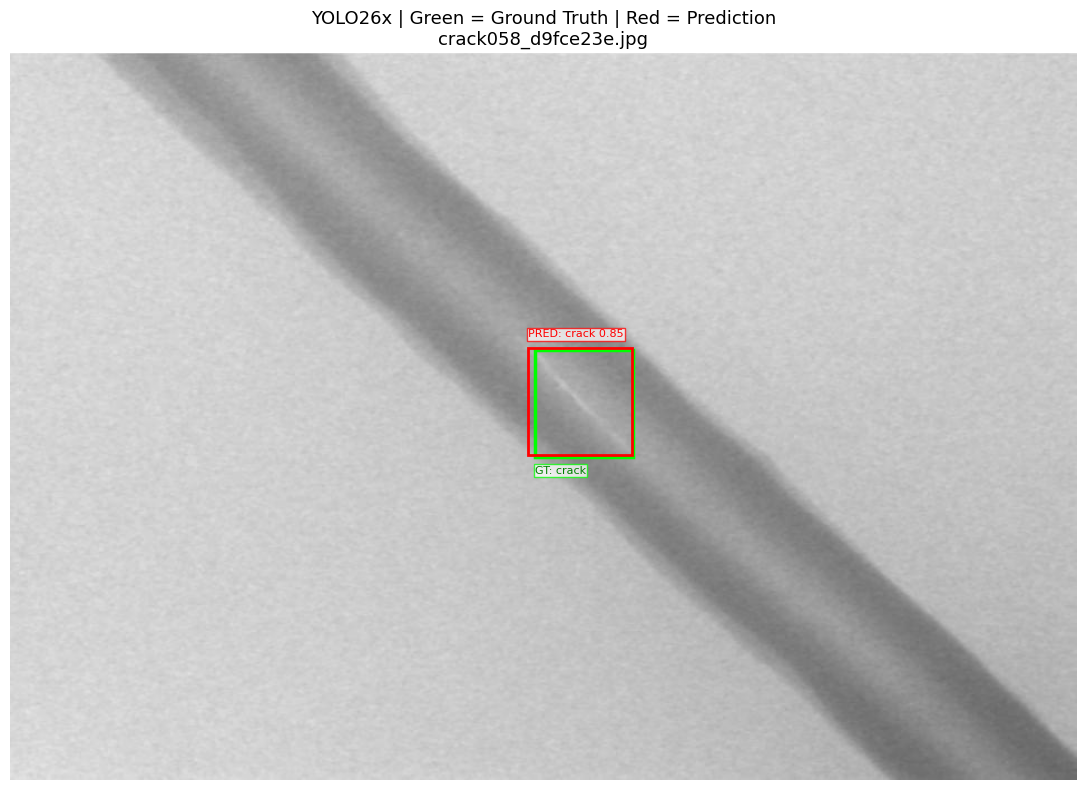

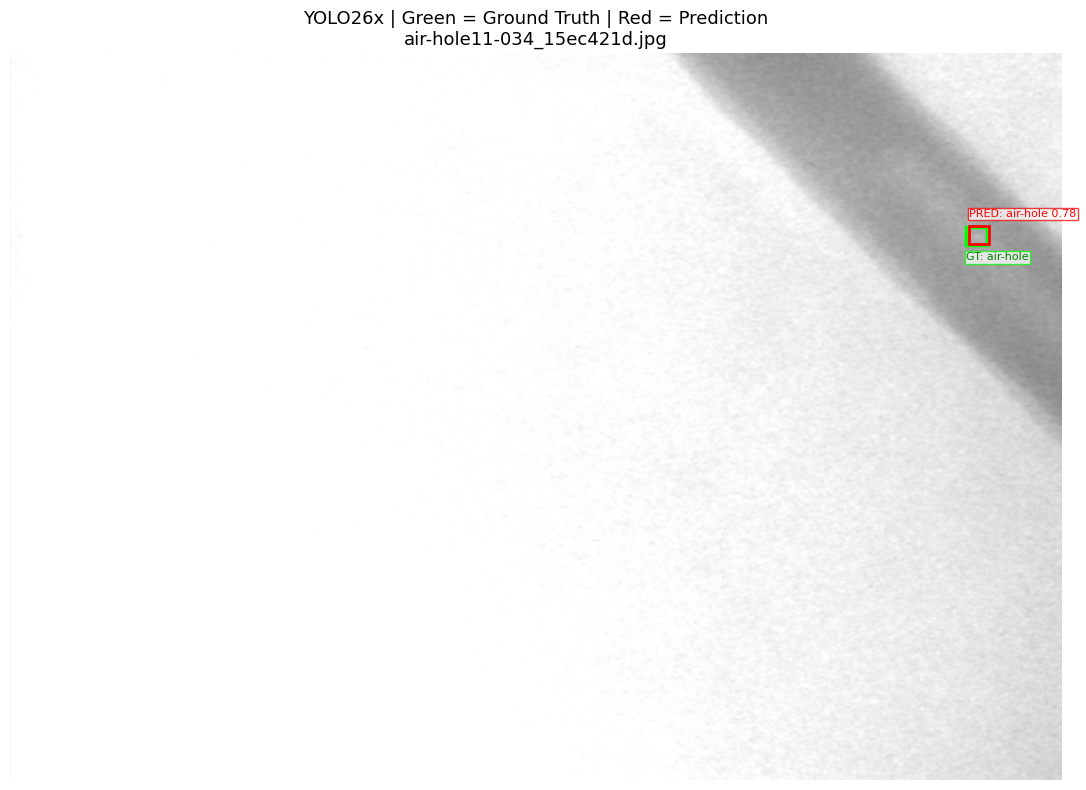

In [ ]:
from ultralytics import YOLO
from pathlib import Path
from PIL import Image

import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches


model = YOLO(
    "/content/drive/MyDrive/RT_weld_project/runs_yolo26/yolo26x_300/weights/best.pt"
)

val_img_dir = Path(
    "/content/drive/MyDrive/RT_weld_project/weld_yolo/images/val"
)

val_label_dir = Path(
    "/content/drive/MyDrive/RT_weld_project/weld_yolo/labels/val"
)

images = sorted(val_img_dir.glob("*"))

random.seed(42)
sample_images = random.sample(images, 10)

results = model.predict(
    source=[str(x) for x in sample_images],
    imgsz=640,
    conf=0.25,
    verbose=False
)


for i, r in enumerate(results):

    image_path = sample_images[i]
    img = Image.open(image_path).convert("RGB")

    width, height = img.size

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(img)

    # =========================
    # GT = 초록색
    # =========================
    label_path = val_label_dir / f"{image_path.stem}.txt"

    if label_path.exists():

        with open(label_path, "r") as f:
            lines = f.readlines()

        for line in lines:

            cls, xc, yc, w, h = map(float, line.strip().split())
            cls = int(cls)

            x1 = (xc - w / 2) * width
            y1 = (yc - h / 2) * height
            x2 = (xc + w / 2) * width
            y2 = (yc + h / 2) * height

            class_name = r.names[cls]

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2.5,
                edgecolor="lime",
                facecolor="none"
            )

            ax.add_patch(rect)

            # GT 라벨은 박스 아래
            gt_y = min(height - 5, y2 + 8)

            ax.text(
                x1,
                gt_y,
                f"GT: {class_name}",
                fontsize=8,
                color="green",
                verticalalignment="top",
                bbox=dict(
                    facecolor="white",
                    edgecolor="lime",
                    alpha=0.75,
                    pad=1
                )
            )

    # =========================
    # PRED = 빨간색
    # =========================
    for box in r.boxes:

        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

        conf = float(box.conf[0])
        cls = int(box.cls[0])

        class_name = r.names[cls]

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        # PRED 라벨은 박스 위
        pred_y = max(5, y1 - 8)

        ax.text(
            x1,
            pred_y,
            f"PRED: {class_name} {conf:.2f}",
            fontsize=8,
            color="red",
            verticalalignment="bottom",
            bbox=dict(
                facecolor="white",
                edgecolor="red",
                alpha=0.75,
                pad=1
            )
        )

    ax.set_title(
        f"YOLO26x | Green = Ground Truth | Red = Prediction\n{image_path.name}",
        fontsize=13
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()